<a href="https://colab.research.google.com/github/moratodpg/risk_reliability/blob/main/mini_project/Evacuation_Mini_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
## When runnning in Google Colab, this cell will clone the repository and install the required packages. 
## You can ignore it if you are running the notebook locally.

import os

if "COLAB_RELEASE_TAG" in os.environ:
    pass  # Optional version control configuration

!git clone -q https://github.com/moratodpg/risk_reliability.git

%cd risk_reliability/mini_project
%pip install -q -r requirements.txt

# Evacuation under uncertainty: student environment

Each person has a position, response delay, walking speed and exit choice. Travel leads to a first-in, first-out (FIFO) queue at each door. Queues couple the people; free travel has no collision avoidance.
The viewer renders the same schedule used in Monte Carlo. It is a simplified agent-based model, not a validated crowd or fire simulator.

**Run all cells to obtain a working demonstration.** Then fit and justify your own distributions and choose a specific sample size.
Read `PROJECT_BRIEF.md`, `MODEL_GUIDE.md`, and `data/README.md`.

Times are seconds from ignition. The probability estimated here is conditional on the specified fire, functioning notification, and ambulant occupants.


## 1. Setup
Run from this notebook folder. Install `requirements.txt` if needed. No Gym, GPU, ffmpeg or network service is required.


In [2]:
from pathlib import Path
from dataclasses import replace
import sys, time, math
import numpy as np
import pandas as pd
import scipy
from scipy import stats
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from IPython.display import display, HTML

ROOT = Path.cwd()
if not (ROOT / "evacuation_env.py").exists():
    choices = [ROOT / "student", ROOT / "output/Evacuation_Mini_Project/student"]
    ROOT = next((p for p in choices if (p / "evacuation_env.py").exists()), ROOT)
if not (ROOT / "evacuation_env.py").exists():
    raise FileNotFoundError("Open this notebook with its folder as the working directory")
sys.path.insert(0, str(ROOT))
from evacuation_env import (Distribution, InputModel, DECISIONS, EvacuationEnv,
                            draw_scenario, simulate, monte_carlo, probability_summary)
DATA = ROOT / "data"
FIGURES = ROOT / "figures"
FIGURES.mkdir(exist_ok=True)
plt.rcParams.update({"font.size": 10, "axes.spines.top": False,
                     "axes.spines.right": False, "figure.dpi": 110})
print({"numpy": np.__version__, "scipy": scipy.__version__, "pandas": pd.__version__,
       "matplotlib": matplotlib.__version__})


{'numpy': '2.2.6', 'scipy': '1.15.3', 'pandas': '2.3.3', 'matplotlib': '3.10.9'}


## 2. Inspect the historical observations

These are independent synthetic trials, not repeated readings from one storm or
one person. The alarm delay and response component are shared by an entire
evacuation event; speed is sampled separately for each person.

**Student task:** assess the observation unit, positive support, sample size, and
tail behaviour. Compare at least lognormal and gamma models for all three inputs.
The worked alarm example below can be adapted to the other two datasets.


,n,mean,sd,min,max
detection,80.0,35.178,10.932,14.598,61.834
response,60.0,44.176,15.293,11.907,76.693
speed,100.0,1.232,0.203,0.818,1.731


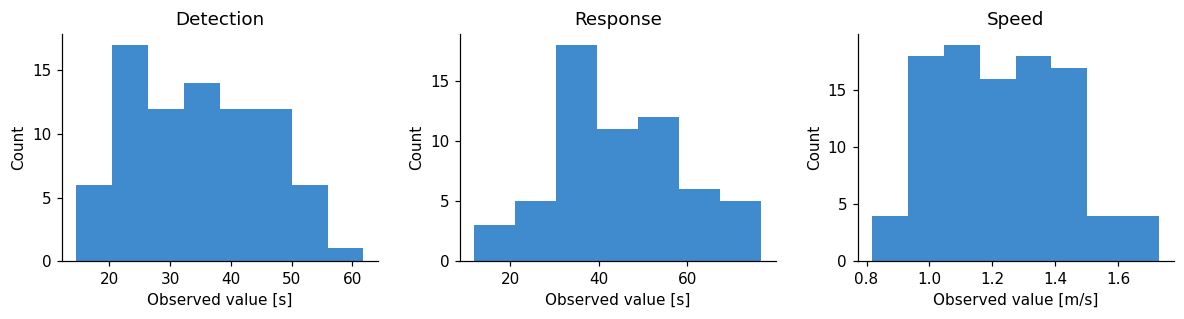

In [3]:
observations = {
    "detection": pd.read_csv(DATA / "alarm_trials.csv")["alarm_delay_s"].to_numpy(),
    "response": pd.read_csv(DATA / "response_drills.csv")["shared_response_s"].to_numpy(),
    "speed": pd.read_csv(DATA / "walking_trials.csv")["free_speed_m_s"].to_numpy(),
}
display(pd.DataFrame({name: {"n": len(x), "mean": x.mean(), "sd": x.std(ddof=1),
                              "min": x.min(), "max": x.max()}
                      for name, x in observations.items()}).T.round(3))
fig, axes = plt.subplots(1, 3, figsize=(11, 3))
for ax, (name, x), unit in zip(axes, observations.items(), ["s", "s", "m/s"]):
    ax.hist(x, bins="auto", color="#0065bd", alpha=.75)
    ax.set(title=name.capitalize(), xlabel=f"Observed value [{unit}]", ylabel="Count")
fig.tight_layout()
fig.savefig(FIGURES / "01_historical_data.png", bbox_inches="tight")
plt.show()


## 3. A worked example: alarm delay

Maximum likelihood fits below fix location to zero so the chosen models have
support above zero. Both have **two fitted parameters**, so Akaike Information Criterion (AIC) uses k = 2.

$AIC = 2k - 2 ln (\hat{L}),$

where $k$ stands for the number of parameters and $\hat{L}$ represents the likelihood.

A lower AIC measures relative fit within the candidates; it does not establish
the true distribution or validate its extrapolated tail. The Q-Q plot compares
theoretical quantiles with sorted observations.

SciPy's lognormal `s` is the SD of log(X), and `scale` is exp(mean(log(X))).
The simulator instead accepts arithmetic mean and CoV; conversion is explicit.


,AIC,mean,cv
family,,,
lognormal,610.2934,35.2297,0.3280
gamma,609.2558,35.1777,0.3125


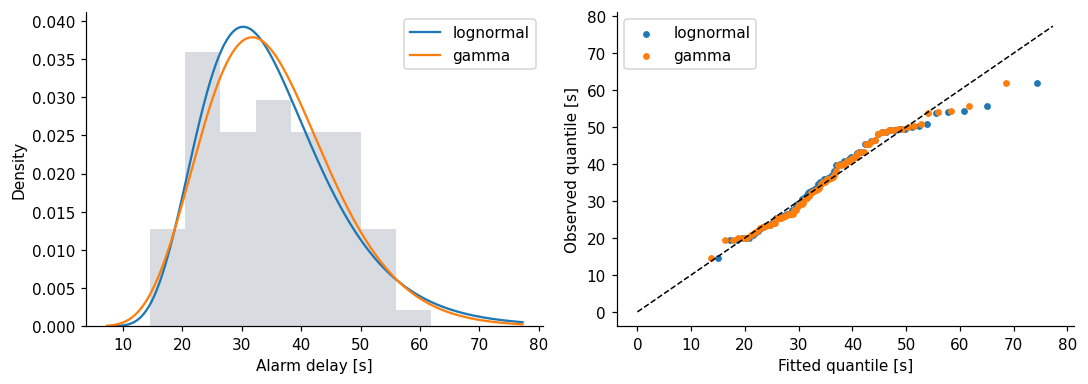

In [6]:
def fit_candidates(x):
    x = np.asarray(x)
    if np.any(x <= 0):
        raise ValueError("These two candidate models require positive observations")
    fits, rows = {}, []
    for name, family in [("lognormal", stats.lognorm), ("gamma", stats.gamma)]:
        parameters = family.fit(x, floc=0)
        fitted = family(*parameters)
        fits[name] = fitted
        rows.append({"family": name, "AIC": 2*2-2*fitted.logpdf(x).sum(),
                     "mean": fitted.mean(), "cv": fitted.std()/fitted.mean()})
    return fits, pd.DataFrame(rows).set_index("family")

alarm_fits, alarm_comparison = fit_candidates(observations["detection"])

display(alarm_comparison.round(4))

x = observations["detection"]

fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
grid = np.linspace(max(.01, x.min()*.5), x.max()*1.25, 300)
axes[0].hist(x, bins="auto", density=True, alpha=.25, color="#64748b")
probabilities = (np.arange(len(x))+.5)/len(x)
for name, fitted in alarm_fits.items():
    axes[0].plot(grid, fitted.pdf(grid), label=name)
    axes[1].scatter(fitted.ppf(probabilities), np.sort(x), s=12, label=name)
axes[1].plot([0, grid.max()], [0, grid.max()], "k--", lw=1)
axes[0].set(xlabel="Alarm delay [s]", ylabel="Density")
axes[1].set(xlabel="Fitted quantile [s]", ylabel="Observed quantile [s]")
for ax in axes:
    ax.legend()
fig.tight_layout()
fig.savefig(FIGURES / "02_alarm_fit.png", bbox_inches="tight")
plt.show()

## 4. Connect your distributions to the simulator

The next cell uses **provisional lognormal moment fits** for all three datasets
so the complete environment runs immediately. These are not final
distribution choices. Replace the choices after your own fit comparison.

For example, after fitting response data you can use
`Distribution("gamma", mean=fitted.mean(), cv=fitted.std()/fitted.mean())`.
Do not confuse scale parameters with standard deviations.

The provided ASET and specific-flow distributions are assumptions, not fits to
these three datasets. All underlying variables are independent in the baseline.
Shared event variables and FIFO queues induce dependence among people.


In [35]:
def provisional_lognormal(x):
    return Distribution("lognormal", mean=float(x.mean()), cv=float(x.std(ddof=0)/x.mean()))

# STUDENT EDIT: replace each entry with your justified family/parameter estimate.
model = InputModel(
    detection=provisional_lognormal(observations["detection"]),
    response=provisional_lognormal(observations["response"]),
    speed=provisional_lognormal(observations["speed"]),
)

display(pd.DataFrame([{"input": name, "family": getattr(model, name).family,
                       "mean": getattr(model, name).mean, "cv": getattr(model, name).cv}
                      for name in ["detection", "response", "speed", "available_time", "flow_per_metre"]]))
display(pd.DataFrame([{"option": d.label, "exit_widths_m": d.exit_widths,
                       "response_multiplier": d.response_factor, "annual_cost_CU": d.annual_cost}
                      for d in DECISIONS.values()]))


,input,family,mean,cv
0,detection,lognormal,35.177667,0.308830
1,response,lognormal,44.175717,0.343298
2,speed,lognormal,1.231997,0.163670
3,available_time,lognormal,175.000000,0.200000
4,flow_per_metre,lognormal,1.200000,0.150000


,option,exit_widths_m,response_multiplier,annual_cost_CU
0,Existing exit,"(1.2, 0.0)",1.0,0.0
1,Evacuation training,"(1.2, 0.0)",0.7,600.0
2,Widen existing exit,"(1.8, 0.0)",1.0,900.0
3,Add second exit,"(1.2, 1.2)",1.0,1800.0


## 5. What happens to one person?

For event-level alarm delay $D$, common response $P$, residual $J_i$ and speed $V_i$:

$$S_i(d)=f_D(d)D+f_P(d)(P+J_i),\qquad B_i(d)=S_i(d)+L_i(d)/V_i.$$

$S_i$ is movement start; $B_i$ is arrival at the assigned door. Each person chooses
the nearest open exit; there is no dynamic rerouting. At door $j$, sort arrivals
and use headway $h_j=1/(q w_j)$:

$$E_{j,k}=\max(B_{j,k},E_{j,k-1})+h_j,\qquad E_{j,0}=0.$$

RSET is the last exit-completion time: $\max_i E_i$. The limit state is
$g=A-\mathrm{RSET}$. ASET and RSET both start at ignition. Waiting, walking and
queuing overlap across different people, so do not sum their durations across
the whole crowd. Each event can be computed directly without time stepping.


,person,start_s,door_arrival_s,exit_finish_s,exit
0,0,53.72,62.38,71.32,1
1,1,55.63,63.37,75.02,1
2,2,60.83,71.91,103.44,1
3,3,61.49,67.17,92.94,1
4,4,55.14,67.60,94.17,1
5,5,57.24,62.58,73.17,1
6,6,61.70,69.16,99.11,1
7,7,58.55,70.49,100.97,1


ASET = 148.13 s; RSET = 106.52 s; g = 41.60 s; failed = False


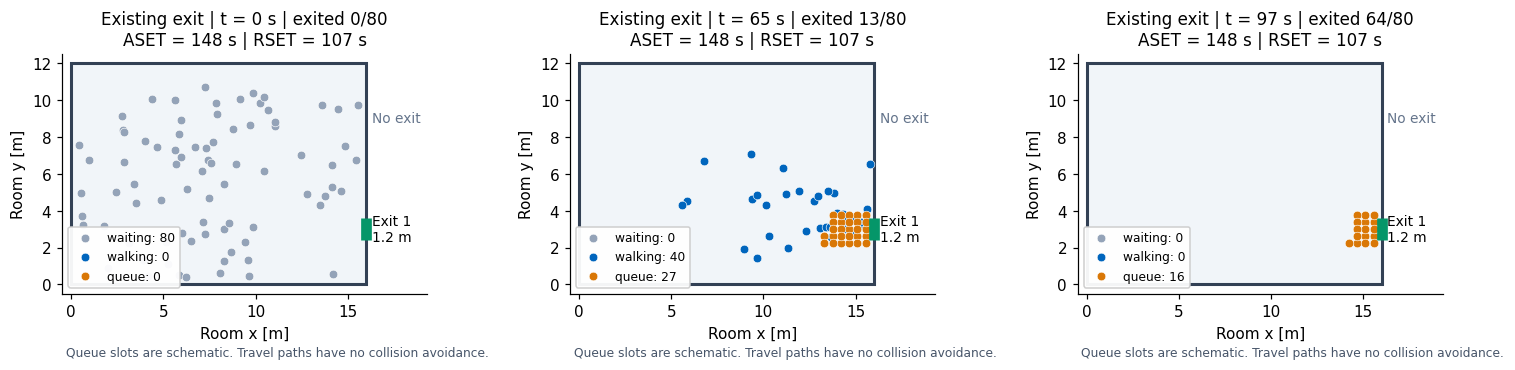

In [9]:
env = EvacuationEnv(model)
env.reset(seed=17, decision=DECISIONS["baseline"])
record = env.record
display(pd.DataFrame({"person": np.arange(len(record["finish"])),
                      "start_s": record["start"], "door_arrival_s": record["arrival"],
                      "exit_finish_s": record["finish"], "exit": record["assigned"]+1
                     }).head(8).round(2))
print(f"ASET = {record['aset']:.2f} s; RSET = {record['rset']:.2f} s; "
      f"g = {record['g']:.2f} s; failed = {record['failed']}")

fig, axes = plt.subplots(1, 3, figsize=(14, 4.5))
times = [0.0, float(np.quantile(record["arrival"], .5)), float(np.quantile(record["finish"], .8))]
for ax, t in zip(axes, times):
    env.time = t
    env.render(ax)
fig.tight_layout()
fig.savefig(FIGURES / "03_room_snapshots.png", bbox_inches="tight")
plt.show()


## 6. RL-style playback: reset, step and render

This is an environment viewer with a familiar `reset` / `step` / `render`
interface. The design is selected at reset. `step(dt)` advances time; it does
not select an action or train an RL agent. Queue slots are schematic display
positions and may jump when the queue advances; the actual queue schedule is
used for the calculations. Exited people disappear and their count increases.
After ASET, a tinted room flags untenability; continuing the schedule does not
imply people could safely keep moving.

The cell stores a self-contained HTML animation. No movie encoder is needed.
Set MAKE_ANIMATION = False for a faster non-visual rerun.


In [10]:
MAKE_ANIMATION = True
if MAKE_ANIMATION:
    viewer = EvacuationEnv(model)
    viewer.reset(seed=17, decision=DECISIONS["baseline"])
    fig, ax = plt.subplots(figsize=(7.4, 5.6))
    fig.subplots_adjust(bottom=.23)  # Keep the model-scope caption in every frame.
    frames = np.linspace(0, viewer.record["rset"], 45)
    def draw_frame(t):
        viewer.time = float(t)
        viewer.render(ax)
        return []
    animation = FuncAnimation(fig, draw_frame, frames=frames, interval=120, repeat=False)
    html = animation.to_jshtml()
    # Remove Matplotlib's optional remote icon font; keep playback fully offline.
    html = html[html.index("<script"):]
    symbols = {"fa-minus": "-", "fa-plus": "+", "fa-fast-backward": "|&lt;&lt;",
               "fa-step-backward": "|&lt;", "fa-play fa-flip-horizontal": "&lt;",
               "fa-pause": "||", "fa-play": "&gt;", "fa-step-forward": "&gt;|",
               "fa-fast-forward": "&gt;&gt;|"}
    for icon, symbol in symbols.items():
        html = html.replace(f'<i class="fa {icon}"></i>', symbol)
    plt.close(fig)
    (FIGURES / "evacuation_animation.html").write_text(html, encoding="utf-8")
    display(HTML(html))
else:
    print("Animation skipped. Simulation results do not depend on this cell.")


## 7. Pilot Monte Carlo: no rendering

Each row is a new independent fire scenario. The **same scenario** is evaluated
under each decision, which gives paired comparisons (common random numbers).
Within a decision, events are independent. Across decisions, results are paired.

$$\hat p_F=N_F/N,\qquad \widehat{SE}=\sqrt{\hat p_F(1-\hat p_F)/N},
\qquad \widehat{CoV}=\widehat{SE}/\hat p_F.$$

The table uses Wilson 95% intervals. Zero failures do not mean zero uncertainty:
SE/CoV are shown as NaN at the extremes, while the interval still has width.
All probabilities are conditional on the specified fire scenario.


In [7]:
PILOT_N = 2000
begin = time.perf_counter()
pilot = monte_carlo(model, n=PILOT_N, seed=20260915)
elapsed = time.perf_counter()-begin
pilot_summary = pd.DataFrame({name: probability_summary(row["failed"])
                              for name, row in pilot.items()}).T
display(pilot_summary.round(5))
print(f"{PILOT_N:,} events x {len(pilot)} options in {elapsed:.2f} s "
      f"({elapsed/PILOT_N*1000:.3f} ms per event across all options).")


2,000 events x 4 options in 0.23 s (0.116 ms per event across all options).


,N,failures,pf,se,cov,ci_low,ci_high
baseline,2000.0,293.0,0.1465,0.00791,0.05397,0.13168,0.16267
training,2000.0,140.0,0.0700,0.00571,0.08150,0.05962,0.08203
wider_exit,2000.0,128.0,0.0640,0.00547,0.08551,0.05409,0.07558
second_exit,2000.0,94.0,0.0470,0.00473,0.10069,0.03856,0.05718


## 8. Choose a production sample size before running it

For target CoV delta and assumed p,
$N=\lceil(1-p)/(p\,\delta^2)\rceil$. This is a planning value based on an uncertain
pilot estimate, not a guarantee of achieved precision. The rarest option
requires the most events for the same relative precision. A zero-failure pilot
requires more information; the code does not silently divide by zero.

Choose one fixed production N after the pilot, and use a fresh seed. Do not
keep stopping/restarting when an ordinary fixed-N confidence interval looks
narrow enough. For this starter demonstration, production is OFF by default.
The suggested 50,000-event ceiling is a runtime prompt, not a statistical rule.


Provisional pilot (N=2,000)


,pf,failures,planned_N
baseline,0.1465,293.0,583
training,0.0700,140.0,1329
wider_exit,0.0640,128.0,1463
second_exit,0.0470,94.0,2028


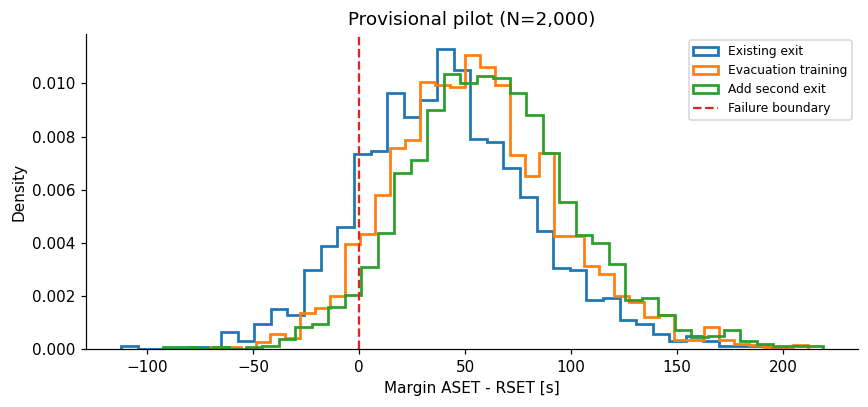

In [8]:
delta = 0.10
plan = pilot_summary[["pf", "failures"]].copy()
plan["planned_N"] = [math.ceil((1-p)/(p*delta**2)) if 0 < p < 1 else np.nan
                     for p in plan["pf"]]
display(plan)
RUN_PRODUCTION = False  # STUDENT EDIT after fitting and sample-size planning.
PRODUCTION_N = 20000    # STUDENT EDIT: justify this value; do not assume it meets delta.
if RUN_PRODUCTION:
    results = monte_carlo(model, n=PRODUCTION_N, seed=20260916)
    analysis_label = f"Production (N={PRODUCTION_N:,})"
else:
    results = pilot
    analysis_label = f"Provisional pilot (N={PILOT_N:,})"
print(analysis_label)

fig, ax = plt.subplots(figsize=(8, 3.8))
for name in ["baseline", "training", "second_exit"]:
    ax.hist(results[name]["g"], bins=40, density=True, histtype="step", lw=1.8,
            label=DECISIONS[name].label)
ax.axvline(0, color="#dc2626", ls="--", label="Failure boundary")
ax.set(xlabel="Margin ASET - RSET [s]", ylabel="Density", title=analysis_label)
ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(FIGURES / "04_margin_distributions.png", bbox_inches="tight")
plt.show()


## 9. Risk, annual costs and paired comparisons

Assumptions: fire-scenario rate $\lambda = 0.02/year$, loss per
time-margin failure $C_F = 1,000,000$ CU. CU is an illustrative cost unit; $C_F$
is not a fatality valuation. All intervention costs are already annualized.

$$R(d)=\lambda \cdot p_F(d\mid\mathrm{fire})C_F,\qquad J(d)=C_{annual}(d)+R(d).$$

$\lambda*p$ is an expected event rate. Under a Poisson fire model, the annual
probability of at least one failed event would be $1-exp(-\lambda*p)$. The expected
loss formula uses the event rate, not that annual probability.

For alternatives evaluated on the same scenarios, compute uncertainty in their
**paired cost differences**. Do not treat their estimates as independent.
This quantifies simulation error only, conditional on the chosen fitted inputs.


In [9]:
FIRE_RATE = 0.02
FAILURE_LOSS = 1_000_000.0
rows = []
baseline_failure = results["baseline"]["failed"].astype(float)
for name, row in results.items():
    d = DECISIONS[name]
    ps = probability_summary(row["failed"])
    annual_risk = FIRE_RATE*FAILURE_LOSS*ps["pf"]
    paired_cost_delta = d.annual_cost + FIRE_RATE*FAILURE_LOSS*(row["failed"]-baseline_failure)
    rows.append({"option": name, "pf": ps["pf"], "annual_risk_CU": annual_risk,
                 "annual_cost_CU": d.annual_cost+annual_risk,
                 "cost_difference_vs_baseline": paired_cost_delta.mean(),
                 "SE_of_paired_difference": paired_cost_delta.std(ddof=1)/np.sqrt(len(paired_cost_delta))})
decision_table = pd.DataFrame(rows).set_index("option")
print(analysis_label, "-- not a final recommendation until input fits and precision are justified")
display(decision_table.round(4))
# A fixed pair is often more useful than separate SEs when options are close.
first, second = "training", "wider_exit"
paired = (DECISIONS[first].annual_cost-DECISIONS[second].annual_cost
          + FIRE_RATE*FAILURE_LOSS*(results[first]["failed"].astype(float)
                                  - results[second]["failed"].astype(float)))
print(f"{first} minus {second}: {paired.mean():.1f} CU/year; "
      f"paired SE = {paired.std(ddof=1)/np.sqrt(len(paired)):.1f} CU/year")


Provisional pilot (N=2,000) -- not a final recommendation until input fits and precision are justified
training minus wider_exit: -180.0 CU/year; paired SE = 61.6 CU/year


,pf,annual_risk_CU,annual_cost_CU,cost_difference_vs_baseline,SE_of_paired_difference
option,,,,,
baseline,0.1465,2930.0,2930.0,0.0,0.0000
training,0.0700,1400.0,2000.0,-930.0,118.8975
wider_exit,0.0640,1280.0,2180.0,-750.0,123.0704
second_exit,0.0470,940.0,2740.0,-190.0,133.8989


## 10. Does the recommendation depend on the loss assumption?

This scaffold varies $C_F$ and keeps estimated probabilities fixed. Interpret switching points and examine at least one assumption.


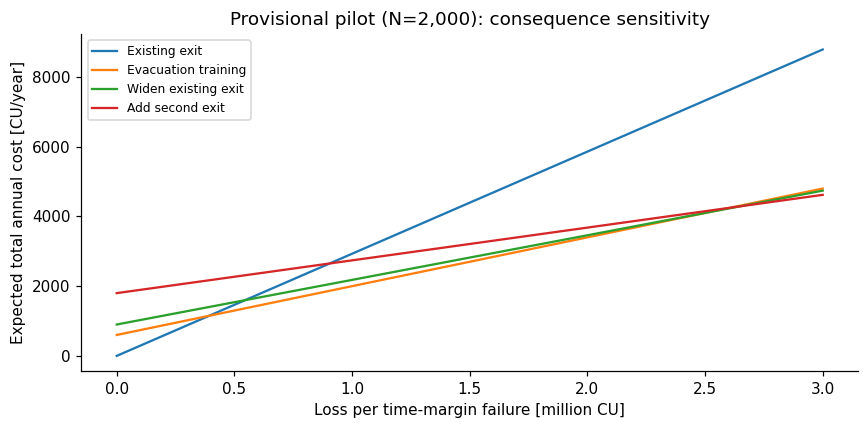

In [10]:
loss_grid = np.linspace(0, 3_000_000, 160)
fig, ax = plt.subplots(figsize=(8, 4))
for name, row in results.items():
    d = DECISIONS[name]
    ax.plot(loss_grid/1e6, d.annual_cost+FIRE_RATE*loss_grid*row["failed"].mean(), label=d.label)
ax.set(xlabel="Loss per time-margin failure [million CU]", ylabel="Expected total annual cost [CU/year]",
       title=analysis_label+": consequence sensitivity")
ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(FIGURES / "05_cost_sensitivity.png", bbox_inches="tight")
plt.show()


## 11. Your model extension

You may implement a extension and explain its effect on the decision, retaining the
baseline for comparison. Possibilities: correlated D/P, a blocked-exit scenario,
uncertain effectiveness, or a different route-choice rule. Modify the helper
module or write a clearly named alternative function; submit that code.


## 13. Submission checklist and sources

- Replace provisional fits and explain the data/model choice.
- Report independent event count, failure count, and achieved simulation precision.
- Keep event-to-event variability, fitted-parameter uncertainty and model limitations distinct.
- Explain conditional probability, event rate, annual risk and annual cost separately.
- An optional extension and one decision sensitivity analysis can be addionally implemented.
- Submit the notebook with its local helper and modified files, plus seeds, and versions.

**Technical references (not sources of the invented parameter values):**

- [NIST: evacuation timeline](https://escape.nist.gov/implementation1) explains detection, notification, response and movement in the RSET concept. The linked course concerns WUI evacuation; it is used here only for the timing concept.
- [SciPy distribution fitting](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.rv_continuous.fit.html): MLE and fixed location parameters.
- [NIST binomial intervals](https://www.itl.nist.gov/div898/handbook/prc/section2/prc241.htm): Wilson and exact intervals.
- [NumPy random streams](https://numpy.org/doc/stable/reference/random/parallel.html): independent seeded streams.

# Templates 

You can reuse the templates provided below for your work.

## Imports

In [11]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from dataclasses import replace
from IPython.display import display
from evacuation_env import Distribution, InputModel, DECISIONS, EvacuationEnv

## Main inputs for the simulator

Edit this cell to build your model. `mean` is the arithmetic mean and
`cv = standard deviation / mean`, for both supported families (`lognormal`
and `gamma`). These family choices are examples, not conclusions from fitting.

| Input | Meaning | Sampling level |
|---|---|---|
| detection | Ignition to alarm/notification [s] | One draw for the entire evacuation |
| response | Common delay after alarm [s] | One draw shared by everyone |
| speed | Unimpeded walking speed [m/s] | One draw per person |
| available_time | Ignition to untenability, ASET [s] | One draw for the entire evacuation |
| flow_per_metre | Door flow [persons/(m s)] | One draw shared by both doors |

Occupancy is discrete uniform between the two bounds, inclusive. Each residual
response delay is uniform between zero and `individual_delay_max`. Positions
are uniform in the room interior [0.4,15.6] x [0.4,11.6] m, as specified in the
provided engine. The baseline underlying draws are independent, but common
inputs and exit queues make individual evacuation times dependent.

In [12]:
model = InputModel(
    detection=Distribution("lognormal", mean=35.0, cv=0.30),
    response=Distribution("gamma", mean=45.0, cv=0.35),
    speed=Distribution("lognormal", mean=1.20, cv=0.18),
    available_time=Distribution("lognormal", mean=175.0, cv=0.20),
    flow_per_metre=Distribution("lognormal", mean=1.20, cv=0.15),
    occupancy_min=50,
    occupancy_max=90,
    individual_delay_max=12.0,
)

## Lognormal: random samples

In [10]:
def lognormal_draw(rng, mean, cv, size=None):
    log_sd = np.sqrt(np.log1p(cv**2))
    log_mean = np.log(mean) - 0.5*log_sd**2
    return rng.lognormal(mean=log_mean, sigma=log_sd, size=size)

## Look at one distribution

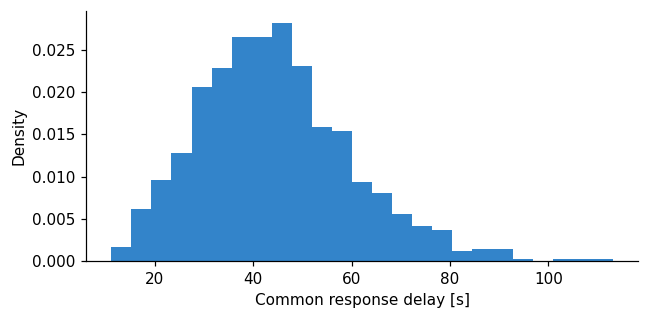

In [13]:
rng = np.random.default_rng(42)
samples = model.response.sample(rng, size=1000)

plt.figure(figsize=(6, 3))
plt.hist(samples, bins=25, density=True, color="#0065bd", alpha=.8)
plt.xlabel("Common response delay [s]")
plt.ylabel("Density")
plt.tight_layout()
plt.show()

## Generate one scenario

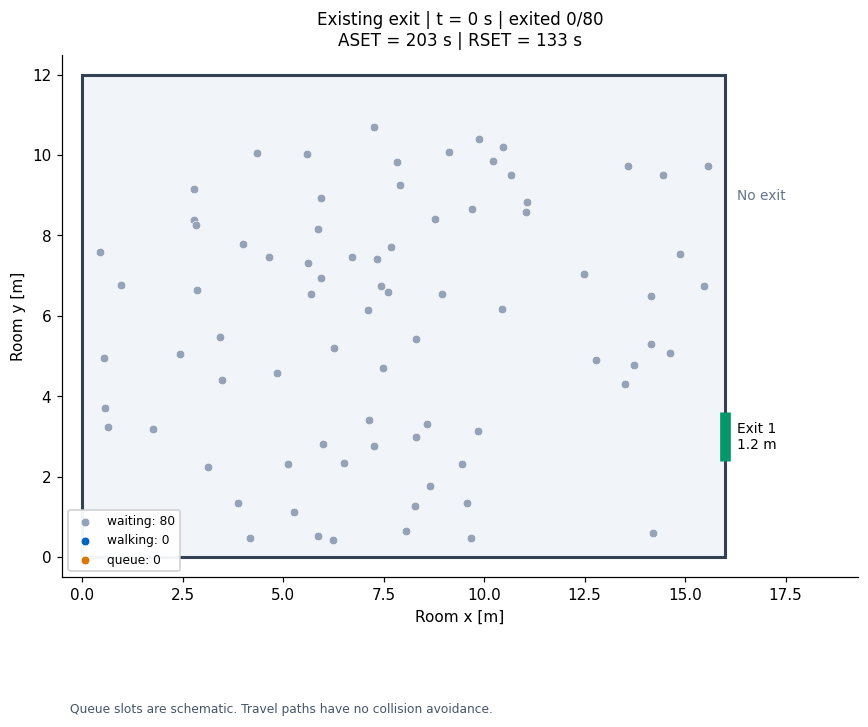

In [26]:
SCENARIO_SEED = 17  # Change this to explore another evacuation scenario.
env = EvacuationEnv(model)
observation = env.reset(seed=SCENARIO_SEED, decision=DECISIONS["baseline"])

env.render()
plt.tight_layout()
plt.show()

Time [s]: 60.0
People outside: 2
Everyone outside: False
ASET reached: False


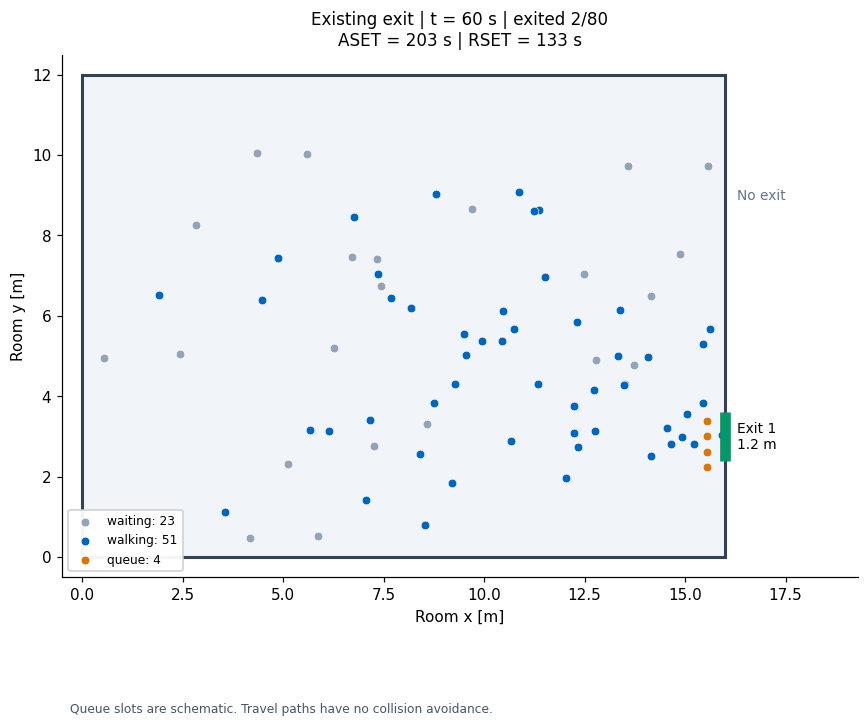

In [27]:
observation = env.step(dt=60)

print("Time [s]:", round(observation["time"], 2))
print("People outside:", observation["exited"])
print("Everyone outside:", observation["done"])
print("ASET reached:", observation["untenable"])
env.render()
plt.tight_layout()
plt.show()


In [30]:
scenario = env.record["scenario"]
print("Number of people:", len(scenario.speeds))
print("Alarm delay D [s]:", round(scenario.detection, 2))
print("Common response P [s]:", round(scenario.response, 2))
print("Available time A [s]:", round(scenario.available_time, 2))
print("Specific flow Q [persons/(m s)]:", round(scenario.flow_per_metre, 3))

display(pd.DataFrame({
    "speed_m_s": scenario.speeds,
    "residual_J_s": scenario.individual_delays,
    "response_P_plus_J_s": scenario.response+scenario.individual_delays,
}).head(16).round(2))

Number of people: 80
Alarm delay D [s]: 16.35
Common response P [s]: 34.77
Available time A [s]: 203.48
Specific flow Q [persons/(m s)]: 0.893


,speed_m_s,residual_J_s,response_P_plus_J_s
0,1.57,3.26,38.03
1,1.26,5.17,39.95
2,0.85,10.38,45.15
3,1.48,11.03,45.80
4,1.20,4.69,39.46
5,1.21,6.78,41.56
6,0.85,11.25,46.02
7,1.27,8.09,42.86
8,1.08,0.57,35.34
9,1.40,5.09,39.86


In [31]:
record = env.record
display(pd.DataFrame({
    "start_s": record["start"],
    "door_arrival_s": record["arrival"],
    "exit_finish_s": record["finish"],
    "exit_number": record["assigned"]+1,
}).head(6).round(2))

A = scenario.available_time
RSET = record["finish"].max()
g = A-RSET
print(f"ASET={A:.2f} s; RSET={RSET:.2f} s; margin={g:.2f} s")
print("Failure:", g <= 0)

,start_s,door_arrival_s,exit_finish_s,exit_number
0,54.39,63.09,79.48,1
1,56.30,64.22,85.08,1
2,61.50,73.25,128.02,1
3,62.16,67.90,109.35,1
4,55.81,68.62,114.02,1
5,57.91,63.39,80.42,1


ASET=203.48 s; RSET=132.69 s; margin=70.78 s
Failure: False


In [32]:
record

{'rset': 132.69060412401797,
 'aset': 203.47536732027834,
 'g': 70.78476319626037,
 'failed': False,
 'late_people': 0,
 'occupancy': 80,
 'scenario': Scenario(positions=array([[ 2.84679099,  6.64673893],
        [ 5.99481511,  2.80734999],
        [ 6.26452537,  5.19544239],
        [ 9.69241525,  8.64752175],
        [ 0.63240278,  3.24525823],
        [ 9.58301699,  1.33785098],
        [15.56600795,  9.72227659],
        [ 0.95901584,  6.75644591],
        [ 9.66197008,  0.47757769],
        [ 3.12207488,  2.24712879],
        [ 7.42176022,  6.7504405 ],
        [ 7.2690202 , 10.70148762],
        [12.78684794,  4.89305981],
        [ 3.48805566,  4.41324603],
        [13.50293255,  4.30673421],
        [15.46419746,  6.736611  ],
        [ 4.00005697,  7.77740982],
        [10.43544297,  6.16360482],
        [ 4.64221317,  7.4550838 ],
        [ 7.68370052,  7.71683473],
        [ 8.64205221,  1.75756482],
        [14.21281799,  0.59278852],
        [ 5.12356156,  2.31927189],
   

## Change a distribution and try again

In [33]:
slower_model = replace(
    model,
    speed=Distribution(model.speed.family, mean=0.80, cv=model.speed.cv),
)
slower_env = EvacuationEnv(slower_model)
slower_env.reset(seed=SCENARIO_SEED, decision=DECISIONS["baseline"])

print("Original RSET [s]:", round(env.record["rset"], 2))
print("Slower crowd RSET [s]:", round(slower_env.record["rset"], 2))

Original RSET [s]: 132.69
Slower crowd RSET [s]: 134.1


## Compare decisions in the same scenario

In [34]:
for name in ["baseline", "training", "wider_exit", "second_exit"]:
    trial = EvacuationEnv(model)
    trial.reset(seed=SCENARIO_SEED, decision=DECISIONS[name])
    rset = trial.record["finish"].max()
    margin = trial.record["scenario"].available_time-rset
    print(f"{name:12s} RSET={rset:7.2f} s   margin={margin:7.2f} s")

baseline     RSET= 132.69 s   margin=  70.78 s
training     RSET= 121.05 s   margin=  82.42 s
wider_exit   RSET= 107.80 s   margin=  95.68 s
second_exit  RSET=  96.26 s   margin= 107.22 s


## Try a few different realizations

In [36]:
rows = []
for seed in range(10):
    trial = EvacuationEnv(model)
    trial.reset(seed=seed, decision=DECISIONS["baseline"])
    r = trial.record
    g = r["scenario"].available_time-r["finish"].max()
    rows.append({"seed": seed, "people": len(r["finish"]),
                 "ASET_s": r["scenario"].available_time,
                 "RSET_s": r["finish"].max(), "margin_s": g, "failed": g <= 0})

display(pd.DataFrame(rows).round(2))

,seed,people,ASET_s,RSET_s,margin_s,failed
0,0,84,184.23,145.09,39.14,False
1,1,69,170.25,149.19,21.06,False
2,2,84,179.59,157.32,22.27,False
3,3,83,168.00,120.59,47.41,False
4,4,79,180.71,139.82,40.90,False
5,5,77,151.17,119.92,31.25,False
6,6,68,138.83,129.45,9.37,False
7,7,88,142.39,183.16,-40.77,True
8,8,79,139.89,128.20,11.69,False
9,9,67,227.98,136.27,91.71,False
